# Tydzień 5: Analiza wyników

Projekt: **Automatyczne streszczanie artykułów**. Model: `bart-base` fine-tunowany w Colabie (`04_trening_colab.ipynb`).

Cel: porównać model z baseline'ami nie tylko jedną liczbą, ale odpowiedzieć na pytania pomocnicze z tygodnia 1:
1. Czy model gorzej streszcza długie artykuły (> 1024 tokenów), które są obcinane?
2. Czy model streszcza cały artykuł, czy głównie jego początek?
3. Jak często model podaje fakty, których nie ma w artykule?

Wszystko liczy się na Macu, bez GPU. Wolne obliczenia (TextRank ~7 min, BERTScore ~11 min) zapisują się w `reports/`.

## A1. Dane i predykcje

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import evaluate

KATALOG = Path("..").resolve()
RAPORTY = KATALOG / "reports"
SEED = 42

test = pd.read_parquet(KATALOG / "data" / "processed" / "test.parquet")   # artykuły oczyszczone, streszczenia redakcji bez zmian
pred = pd.read_parquet(RAPORTY / "predykcje_test_bart-base_lr5e-05_ep1.parquet")
assert (test["id"].values == pred["id"].values).all(), "kolejność predykcji nie zgadza się z testem"

nltk.download("punkt_tab", quiet=True)
streszczenia = pd.DataFrame({
    "Lead-3": ["\n".join(nltk.sent_tokenize(a)[:3]) for a in test["article"]],
    "bart-base": pred["predykcja"].values,
})
print(len(test), "artykułów testowych")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[nltk_data] Error loading punkt_tab: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1010)>


11490 artykułów testowych


## A2. Baseline 2: TextRank

TextRank (biblioteka `sumy`) to metoda **ekstrakcyjna**: buduje graf zdań artykułu, w którym zdania są połączone, jeśli mają wspólne słowa, i wybiera 3 „najważniejsze” zdania, podobnie jak PageRank wybiera ważne strony. W przeciwieństwie do Lead-3 może wybrać zdania z dowolnego miejsca artykułu.

In [2]:
from sumy.parsers.plaintext import PlaintextParser
from sumy.nlp.tokenizers import Tokenizer
from sumy.summarizers.text_rank import TextRankSummarizer

plik_textrank = RAPORTY / "predykcje_test_textrank.parquet"
if plik_textrank.exists():
    streszczenia["TextRank"] = pd.read_parquet(plik_textrank)["predykcja"].values
    print("Wczytano zapisane streszczenia TextRank")
else:
    textrank = TextRankSummarizer()
    def streszcz_textrank(tekst, zdania=3):
        dokument = PlaintextParser.from_string(tekst, Tokenizer("english")).document
        return "\n".join(str(z) for z in textrank(dokument, zdania))
    streszczenia["TextRank"] = [streszcz_textrank(a) for a in test["article"]]   # ok. 7 minut
    pd.DataFrame({"id": test["id"], "predykcja": streszczenia["TextRank"]}).to_parquet(plik_textrank, index=False)

streszczenia = streszczenia[["Lead-3", "TextRank", "bart-base"]]
print(streszczenia["TextRank"].iloc[0])

Wczytano zapisane streszczenia TextRank
"As Palestine formally becomes a State Party to the Rome Statute today, the world is also a step closer to ending a long era of impunity and injustice," he said, according to an ICC news release.
Judge Kuniko Ozaki, a vice president of the ICC, said acceding to the treaty was just the first step for the Palestinians.
"As the Rome Statute today enters into force for the State of Palestine, Palestine acquires all the rights as well as responsibilities that come with being a State Party to the Statute.


## A3. ROUGE dla każdego artykułu osobno

Do tej pory liczyłam jedną średnią dla całego zbioru. Teraz zapisuje ROUGE **dla każdego artykułu**, żeby porównywać grupy artykułów (A6), testować istotność różnic (A5) i poszukać najlepszych i najgorszych przykładów (A9).

In [3]:
rouge = evaluate.load("rouge")
referencje = ["\n".join(nltk.sent_tokenize(h)) for h in test["highlights"]]

wyniki = {}
for system in streszczenia.columns:
    predykcje = ["\n".join(nltk.sent_tokenize(s)) for s in streszczenia[system]]
    r = rouge.compute(predictions=predykcje, references=referencje, use_stemmer=True, use_aggregator=False)
    for metryka in ["rouge1", "rouge2", "rougeLsum"]:
        wyniki[(system, metryka)] = np.array(r[metryka]) * 100

rouge_df = pd.DataFrame(wyniki)
rouge_df.mean().unstack().round(2)

,rouge1,rouge2,rougeLsum
Lead-3,40.06,17.48,36.37
TextRank,29.71,9.99,26.46
bart-base,41.06,18.63,37.98


## A4. BERTScore

ROUGE liczy **wspólne słowa**, więc parafraza („Palestine joined the ICC” vs „Palestinian Authority becomes member of the ICC”) dostaje niski wynik, mimo że znaczy to samo. **BERTScore** porównuje znaczenie: zamienia słowa na wektory (embeddingi z modelu `roberta-large`, lekcja 34) i sprawdza, jak bardzo są podobne.

Wyniki są przeskalowane (`rescale_with_baseline=True`), żeby 0 oznaczało poziom losowych zdań. Wartości są przez to niższe niż w niektórych publikacjach, ale porównanie systemów między sobą jest uczciwe.

In [4]:
plik_bertscore = RAPORTY / "bertscore_test.parquet"
if plik_bertscore.exists():
    bertscore = pd.read_parquet(plik_bertscore)
    print("Wczytano zapisany BERTScore")
else:
    import torch
    from bert_score import BERTScorer
    urzadzenie = "mps" if torch.backends.mps.is_available() else "cpu"
    scorer = BERTScorer(model_type="roberta-large", lang="en", rescale_with_baseline=True, device=urzadzenie)
    bertscore = pd.DataFrame({
        system: scorer.score(streszczenia[system].tolist(), test["highlights"].tolist(), batch_size=32)[2].numpy() * 100
        for system in streszczenia.columns                                         # ok. 4 minuty na system
    })
    bertscore.to_parquet(plik_bertscore, index=False)

bertscore.mean().round(2)

Wczytano zapisany BERTScore


Lead-3       25.49
TextRank     14.00
bart-base    28.77
dtype: float32

## A5. Tabela wyników i istotność różnic

Sprawdzam **bootstrapem**: losuje ze zwracaniem 1000 razy po 11 490 artykułów i za każdym razem liczę różnicę średnich. 95% przedział ufności, który nie zawiera zera, oznacza istotną różnicę.

In [5]:
dlugosc = streszczenia.apply(lambda kol: kol.str.split().str.len().mean())
dlugosc["Redakcja"] = test["highlights"].str.split().str.len().mean()

tabela = rouge_df.mean().unstack()
tabela["BERTScore F1"] = bertscore.mean()
tabela.loc["bart-large-cnn (literatura)"] = [44.16, 21.28, 40.90, np.nan]
tabela["średnia długość (słowa)"] = dlugosc
tabela = tabela.round(2)
tabela.to_csv(RAPORTY / "tabela_wynikow.csv")
print(f"Długość streszczeń redakcji: {dlugosc['Redakcja']:.1f} słowa")
tabela

Długość streszczeń redakcji: 55.0 słowa


,rouge1,rouge2,rougeLsum,BERTScore F1,średnia długość (słowa)
Lead-3,40.06,17.48,36.37,25.49,76.44
TextRank,29.71,9.99,26.46,14.00,105.96
bart-base,41.06,18.63,37.98,28.77,57.71
bart-large-cnn (literatura),44.16,21.28,40.90,NaN,NaN


In [6]:
rng = np.random.default_rng(SEED)

def przedzial_bootstrap(a, b, n=1000):
    """95% przedział ufności dla różnicy średnich a - b (te same artykuły, próba sparowana)."""
    roznice = a - b
    indeksy = rng.integers(0, len(roznice), size=(n, len(roznice)))
    srednie = roznice[indeksy].mean(axis=1)
    return roznice.mean(), np.percentile(srednie, 2.5), np.percentile(srednie, 97.5)

porownania = []
for metryka, dane in [("ROUGE-2", lambda s: rouge_df[(s, "rouge2")].values),
                      ("BERTScore", lambda s: bertscore[s].values)]:
    for baseline in ["Lead-3", "TextRank"]:
        srednia, dol, gora = przedzial_bootstrap(dane("bart-base"), dane(baseline))
        porownania.append({"metryka": metryka, "porównanie": f"bart-base − {baseline}",
                           "różnica": round(srednia, 2), "95% CI": f"[{dol:.2f}, {gora:.2f}]",
                           "istotna": "tak" if dol > 0 or gora < 0 else "nie"})

wygrane = (rouge_df[("bart-base", "rouge2")] > rouge_df[("Lead-3", "rouge2")]).mean()
print(f"bart-base ma wyższy ROUGE-2 niż Lead-3 w {wygrane:.1%} artykułów")
pd.DataFrame(porownania)

bart-base ma wyższy ROUGE-2 niż Lead-3 w 53.7% artykułów


,metryka,porównanie,różnica,95% CI,istotna
0,ROUGE-2,bart-base − Lead-3,1.15,"[0.97, 1.34]",tak
1,ROUGE-2,bart-base − TextRank,8.64,"[8.42, 8.85]",tak
2,BERTScore,bart-base − Lead-3,3.28,"[3.07, 3.48]",tak
3,BERTScore,bart-base − TextRank,14.77,"[14.53, 15.04]",tak


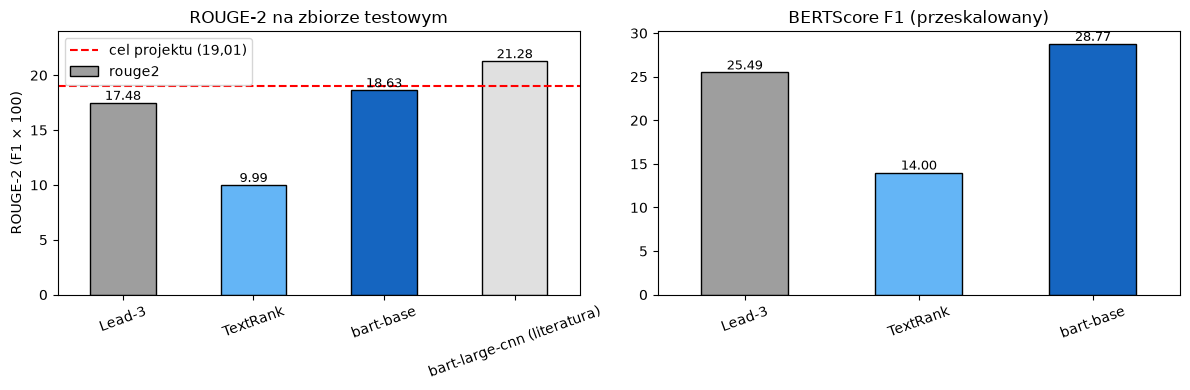

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
kolory = ["#9e9e9e", "#64b5f6", "#1565c0", "#e0e0e0"]
tabela["rouge2"].plot.bar(ax=axes[0], color=kolory, edgecolor="black")
axes[0].axhline(19.01, color="red", linestyle="--", label="cel projektu (19,01)")
axes[0].set_title("ROUGE-2 na zbiorze testowym")
axes[0].set_ylabel("ROUGE-2 (F1 × 100)")
axes[0].set_ylim(0, 24)
axes[0].legend()
tabela["BERTScore F1"].dropna().plot.bar(ax=axes[1], color=kolory[:3], edgecolor="black")
axes[1].set_title("BERTScore F1 (przeskalowany)")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
    for slupek in ax.patches:
        ax.annotate(f"{slupek.get_height():.2f}", (slupek.get_x() + slupek.get_width() / 2, slupek.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(RAPORTY / "porownanie_systemow.png", dpi=100, bbox_inches="tight")
plt.show()

## A6. Pytanie pomocnicze 1: czy obcinanie szkodzi?

BART czyta maksymalnie 1024 tokeny, więc dłuższe artykuły są obcinane (ok. 30% testu). Jeśli obcinanie szkodzi, przewaga modelu nad Lead-3 powinna być mniejsza dla długich artykułów. Lead-3 obcinanie nie dotyczy, bo zawsze patrzy tylko na początek.

In [8]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("facebook/bart-base")
test["tokeny"] = [len(x) for x in tokenizer(test["article"].tolist())["input_ids"]]
test["długość"] = pd.cut(test["tokeny"], bins=[0, 512, 1024, 1536, np.inf],
                         labels=["≤ 512", "513–1024", "1025–1536", "> 1536"])

r2 = pd.DataFrame({s: rouge_df[(s, "rouge2")] for s in streszczenia.columns})
r2["długość"] = test["długość"].values
wg_dlugosci = r2.groupby("długość", observed=True).mean().round(2)
wg_dlugosci["bart-base − Lead-3"] = (wg_dlugosci["bart-base"] - wg_dlugosci["Lead-3"]).round(2)
wg_dlugosci["liczba artykułów"] = r2.groupby("długość", observed=True).size()
wg_dlugosci

,Lead-3,TextRank,bart-base,bart-base − Lead-3,liczba artykułów
długość,,,,,
≤ 512,20.37,14.10,21.57,1.20,2754
513–1024,17.68,9.79,18.69,1.01,5424
1025–1536,15.33,7.26,16.65,1.32,2305
> 1536,13.46,6.13,14.87,1.41,1007


In [9]:
obciete = test["tokeny"] > 1024
pd.DataFrame({
    "≤ 1024 (cały artykuł)": r2[~obciete.values].drop(columns="długość").mean(),
    "> 1024 (obcięty)": r2[obciete.values].drop(columns="długość").mean(),
}).T.round(2)

,Lead-3,TextRank,bart-base
≤ 1024 (cały artykuł),18.58,11.24,19.66
> 1024 (obcięty),14.76,6.92,16.11


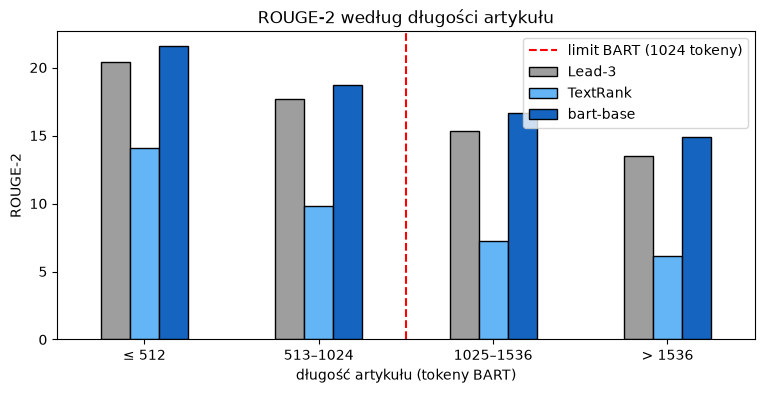

In [10]:
ax = wg_dlugosci[["Lead-3", "TextRank", "bart-base"]].plot.bar(figsize=(9, 4), color=kolory[:3], edgecolor="black")
ax.axvline(1.5, color="red", linestyle="--", label="limit BART (1024 tokeny)")
ax.set_title("ROUGE-2 według długości artykułu")
ax.set_xlabel("długość artykułu (tokeny BART)")
ax.set_ylabel("ROUGE-2")
ax.tick_params(axis="x", rotation=0)
ax.legend()
plt.savefig(RAPORTY / "rouge_wg_dlugosci.png", dpi=100, bbox_inches="tight")
plt.show()

## A7. Pytanie pomocnicze 2: cały artykuł czy początek?

Dwie miary:
- **Pozycja źródłowa:** dla każdego zdania streszczenia szukam najbardziej podobnego zdania artykułu (ta sama metoda co w EDA, E5) i zapisuje jego względną pozycję (0 = początek, 1 = koniec). Porównujem model ze streszczeniami redakcji.
- **Abstrakcyjność:** jaki procent par słów (bigramów) w streszczeniu **nie występuje** w artykule. 0% = streszczenie złożone tylko z fragmentów artykułu (Lead-3, TextRank), wysoki procent = parafraza.

In [11]:
def slowa(tekst):
    return set(re.findall(r"[a-z0-9]+", tekst.lower()))

def pozycje_zrodlowe(artykul, streszczenie):
    zdania_art = nltk.sent_tokenize(artykul)
    slowa_art = [slowa(z) for z in zdania_art]
    wynik = []
    for zdanie in streszczenie.split("\n"):
        s = slowa(zdanie)
        if s:
            pokrycie = [len(s & a) / len(s) for a in slowa_art]
            wynik.append(np.argmax(pokrycie) / len(zdania_art))
    return wynik

probka = test.sample(2000, random_state=SEED).index
pozycje = {
    "Redakcja": [p for i in probka for p in pozycje_zrodlowe(test.at[i, "article"], test.at[i, "highlights"])],
    "bart-base": [p for i in probka for p in pozycje_zrodlowe(test.at[i, "article"], streszczenia.at[i, "bart-base"])],
    "TextRank": [p for i in probka for p in pozycje_zrodlowe(test.at[i, "article"], streszczenia.at[i, "TextRank"])],
}
pd.DataFrame({
    nazwa: {"z pierwszych 10%": np.mean(np.array(p) < 0.1), "z pierwszych 30%": np.mean(np.array(p) < 0.3),
            "z drugiej połowy": np.mean(np.array(p) >= 0.5)}
    for nazwa, p in pozycje.items()
}).mul(100).round(1)

,Redakcja,bart-base,TextRank
z pierwszych 10%,43.9,57.7,19.0
z pierwszych 30%,70.9,87.6,40.9
z drugiej połowy,17.5,6.6,41.2


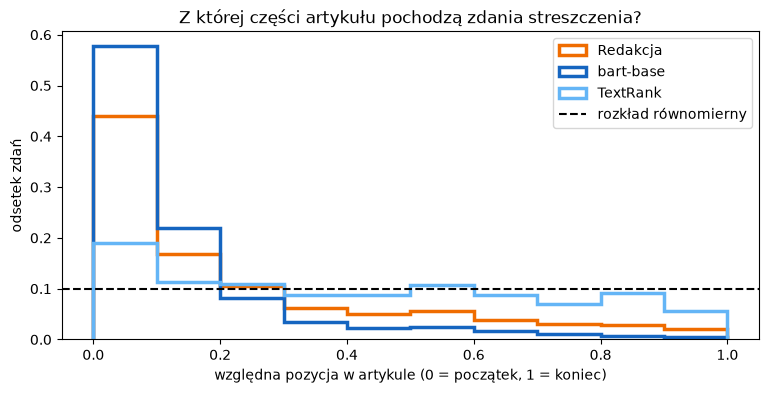

In [12]:
plt.figure(figsize=(9, 4))
for (nazwa, p), kolor in zip(pozycje.items(), ["#ef6c00", "#1565c0", "#64b5f6"]):
    plt.hist(p, bins=10, range=(0, 1), weights=np.ones(len(p)) / len(p), histtype="step", linewidth=2.5, color=kolor, label=nazwa)
plt.axhline(0.1, color="black", linestyle="--", label="rozkład równomierny")
plt.title("Z której części artykułu pochodzą zdania streszczenia?")
plt.xlabel("względna pozycja w artykule (0 = początek, 1 = koniec)")
plt.ylabel("odsetek zdań")
plt.legend()
plt.savefig(RAPORTY / "lead_bias_model.png", dpi=100, bbox_inches="tight")
plt.show()

In [13]:
def bigramy(tekst):
    tokeny = re.findall(r"[a-z0-9]+", tekst.lower())
    return set(zip(tokeny, tokeny[1:]))

def nowe_bigramy(streszczenie, artykul):
    b = bigramy(streszczenie)
    return len(b - bigramy(artykul)) / len(b) * 100 if b else 0.0

abstrakcyjnosc = {nazwa: np.mean([nowe_bigramy(s, test.at[i, "article"]) for i, s in kolumna.loc[probka].items()])
                  for nazwa, kolumna in [("Redakcja", test["highlights"])] + list(streszczenia.items())}
pd.Series(abstrakcyjnosc, name="% nowych bigramów").round(1)

Redakcja     51.2
Lead-3        0.0
TextRank      1.6
bart-base     6.1
Name: % nowych bigramów, dtype: float64

## A8. Pytanie pomocnicze 3: halucynacje (automatyczna ocena spójności faktów)

Sprawdzam automatycznie, czy każde zdanie streszczenia **wynika z artykułu**. Używam modelu **NLI** (natural language inference, `cross-encoder/nli-deberta-v3-base`), który dla pary *(fragment artykułu, zdanie)* ocenia, czy zdanie wynika z fragmentu (*entailment*), jest z nim sprzeczne (*contradiction*) czy żadne z nich (*neutral*). Podobnie działa metoda SummaC, stosowana w badaniach nad streszczeniami.

**Procedura:**
1. Artykuł dzielimy na okna po 2 sąsiednie zdania.
2. Dla każdego zdania streszczenia szukam okna, z którego zdanie wynika najbardziej (maksymalne prawdopodobieństwo *entailment*).
3. Zdanie uznaje za **niepoparte**, jeśli to maksimum jest < 0,5.

**Punkt odniesienia:** Lead-3 tylko kopiuje zdania z artykułu, więc każde jego „niepoparte” zdanie to błąd samej metody. Mówi, jak bardzo NLI zawyża wynik. Dla porównania liczy też streszczenia redakcji, które są pisane własnymi słowami.

Liczę na losowej próbce 500 artykułów testowych (ok. 20 minut przy pierwszym uruchomieniu, potem wynik jest wczytywany z `reports/`).

**Ograniczenia:** NLI nie łączy informacji z odległych części artykułu i myli się przy zaimkach i synonimach (np. „police spokesman” w streszczeniu vs „Aguilar said” w artykule). Wynik to **górne oszacowanie** liczby błędów, a nie dokładna liczba halucynacji.

In [14]:
import torch
from transformers import AutoModelForSequenceClassification

plik_nli = RAPORTY / "nli_test.parquet"
probka_nli = test.sample(500, random_state=SEED).index

if plik_nli.exists():
    nli = pd.read_parquet(plik_nli)
    print("Wczytano zapisaną ocenę NLI")
else:
    MODEL_NLI = "cross-encoder/nli-deberta-v3-base"
    urzadzenie = "mps" if torch.backends.mps.is_available() else "cpu"
    tok_nli = AutoTokenizer.from_pretrained(MODEL_NLI)
    model_nli = AutoModelForSequenceClassification.from_pretrained(MODEL_NLI).to(urzadzenie).eval()
    ENTAILMENT = [k for k, v in model_nli.config.id2label.items() if v.lower() == "entailment"][0]

    def ocen_zdanie(okna, zdanie, batch=64):
        """Najwyższe prawdopodobieństwo, że zdanie wynika z któregoś okna artykułu, i to okno."""
        najlepsze, najlepsze_okno = 0.0, ""
        for i in range(0, len(okna), batch):
            wejscie = tok_nli(okna[i:i + batch], [zdanie] * len(okna[i:i + batch]), truncation=True,
                              max_length=256, padding=True, return_tensors="pt").to(urzadzenie)
            with torch.no_grad():
                p = model_nli(**wejscie).logits.softmax(-1)[:, ENTAILMENT].cpu().numpy()
            if p.max() > najlepsze:
                najlepsze, najlepsze_okno = float(p.max()), okna[i + int(p.argmax())]
        return najlepsze, najlepsze_okno

    wiersze = []
    zrodla = {"Lead-3": streszczenia["Lead-3"], "bart-base": streszczenia["bart-base"], "Redakcja": test["highlights"]}
    for i in probka_nli:
        zdania_art = nltk.sent_tokenize(test.at[i, "article"])
        okna = [" ".join(zdania_art[j:j + 2]) for j in range(len(zdania_art))]
        for system, kolumna in zrodla.items():
            for zdanie in nltk.sent_tokenize(kolumna[i]):
                wynik, okno = ocen_zdanie(okna, zdanie)
                wiersze.append({"indeks": i, "system": system, "zdanie": zdanie, "entailment": wynik, "najblizsze_okno": okno})
    nli = pd.DataFrame(wiersze)
    nli.to_parquet(plik_nli, index=False)

nli["niepoparte"] = nli["entailment"] < 0.5
podsumowanie_nli = pd.DataFrame({
    "% zdań niepopartych": nli.groupby("system")["niepoparte"].mean() * 100,
    "% streszczeń z ≥ 1 niepopartym zdaniem": nli.groupby(["system", "indeks"])["niepoparte"].any().groupby("system").mean() * 100,
    "liczba zdań": nli.groupby("system").size(),
}).loc[["Lead-3", "bart-base", "Redakcja"]].round(1)
podsumowanie_nli

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 9113.44it/s]

,% zdań niepopartych,% streszczeń z ≥ 1 niepopartym zdaniem,liczba zdań
system,,,
Lead-3,11.3,33.6,1501
bart-base,8.2,21.0,1443
Redakcja,32.8,72.0,1858


In [15]:
# Przykłady zdań modelu uznanych za niepoparte: przeczytaj je i porównaj z najbliższym fragmentem artykułu.
# Część to prawdziwe błędy (np. zamiana ról osób), a część to fałszywe alarmy metody (zaimki, synonimy).
niepoparte_model = nli[(nli["system"] == "bart-base") & nli["niepoparte"]].sort_values("entailment")
for _, w in niepoparte_model.sample(min(8, len(niepoparte_model)), random_state=SEED).iterrows():
    print(f"[entailment = {w['entailment']:.2f}]")
    print("  ZDANIE MODELU:      ", w["zdanie"])
    print("  NAJBLIŻSZY FRAGMENT:", w["najblizsze_okno"][:300])
    print()

[entailment = 0.01]
  ZDANIE MODELU:       The incident caused disruption for hundreds of travellers.
  NAJBLIŻSZY FRAGMENT: Photos snapped by travellers show the tip of a winglet dangling by a thread after clipping the other plane - and it's the second time in six months two Ryanair planes have collided at Ireland's busiest airport. Passengers escaped injury when the planes collided as they taxied to a runway shortly bef

[entailment = 0.03]
  ZDANIE MODELU:       It is because the Corporation is extra-wary about causing offence, an editor at the company has claimed.
  NAJBLIŻSZY FRAGMENT: Comics at the BBC must go through a lengthy process to get jokes on air, including some being looked over by director general Lord Hall (left), an editor at the company claimed. It is because the Corporation is extra-wary about causing offence - like in the Sachsgate scandal involving Russell Brand 

[entailment = 0.00]
  ZDANIE MODELU:       The married father-of-two bragged that he 'spared no expe

## A9. Najlepsze i najgorsze streszczenia

Przykłady do prezentacji i do zrozumienia, kiedy model zawodzi.

In [16]:
porownanie = pd.DataFrame({
    "bart-base": rouge_df[("bart-base", "rouge2")].values,
    "Lead-3": rouge_df[("Lead-3", "rouge2")].values,
})
porownanie["przewaga"] = porownanie["bart-base"] - porownanie["Lead-3"]

def pokaz(i, tytul):
    print(f"=== {tytul} | ROUGE-2: model {porownanie.at[i, 'bart-base']:.1f}, Lead-3 {porownanie.at[i, 'Lead-3']:.1f} ===")
    print("ARTYKUŁ:", test.at[i, "article"][:400], "...")
    print("\nREDAKCJA:\n" + test.at[i, "highlights"])
    print("\nMODEL:\n" + streszczenia.at[i, "bart-base"])
    print("\nLEAD-3:\n" + streszczenia.at[i, "Lead-3"][:400])
    print()

pokaz(porownanie["przewaga"].idxmax(), "NAJWIĘKSZA PRZEWAGA MODELU NAD LEAD-3")
pokaz(porownanie["przewaga"].idxmin(), "NAJWIĘKSZA PRZEWAGA LEAD-3 NAD MODELEM")

=== NAJWIĘKSZA PRZEWAGA MODELU NAD LEAD-3 | ROUGE-2: model 93.0, Lead-3 1.9 ===
ARTYKUŁ: Scientists have used cosmic rays from the distant universe to study lightning and thunderclouds in unprecedented detail. Cosmic rays constantly bombard Earth’s atmosphere, and there have been some suggestions they could even trigger lightning. But this particular experiment observed how cosmic rays were affected by lightning as they passed through it - providing information on the electrical field ...

REDAKCJA:
Scientists in The Netherlands were using the Lofar radio telescope .
They found it could measure changes in lightning caused by cosmic rays .
A storm can have hundreds of millions of volts over multiple kilometres .
Method could provide a novel way to understand thunderclouds .

MODEL:
Scientists in The Netherlands were using the Lofar radio telescope.
They found it could measure changes in lightning caused by cosmic rays (illustrated)
A storm can have hundreds of millions of volts over mul

In [17]:
print(f"Streszczenia modelu z ROUGE-2 = 0: {(porownanie['bart-base'] == 0).sum()} ({(porownanie['bart-base'] == 0).mean():.1%})")
najgorsze = porownanie[porownanie["bart-base"] == 0].sample(1, random_state=SEED).index[0]
pokaz(najgorsze, "PRZYKŁAD Z ROUGE-2 = 0")

Streszczenia modelu z ROUGE-2 = 0: 261 (2.3%)
=== PRZYKŁAD Z ROUGE-2 = 0 | ROUGE-2: model 0.0, Lead-3 0.0 ===
ARTYKUŁ: (CNN)Erika Langhart had a zest for life. By the time she finished college she had already visited 37 countries. After graduating from college she was working in Washington and thinking about going to law school. Her life was full of promise, but all that ended suddenly when she was just 24 years old. In Phoenix, Karen Langhart was looking forward to her daughter coming home for Thanksgiving when s ...

REDAKCJA:
The NuvaRing is one of the most popular birth control products on the market .
Lawsuit cites "a heightened risk of blood clots associated with the use of NuvaRing"
Maker: "There is substantial evidence to support the safety and efficacy of NuvaRing"

MODEL:
Erika Langhart had a zest for life.
By the time she finished college she had already visited 37 countries.
After graduating from college she was working in Washington and thinking about going to law school.


## A10. Wnioski

**Tabela wyników (A3–A5)**
- `bart-base` jest najlepszy we wszystkich metrykach: ROUGE-2 18,63 (Lead-3 17,48, TextRank 9,99), BERTScore 28,77 (Lead-3 25,49, TextRank 14,00).
- Przewaga nad Lead-3 jest **istotna statystycznie**: ROUGE-2 +1,15 (95% CI [0,97; 1,34]), BERTScore +3,28 (95% CI [3,07; 3,48]). W BERTScore przewaga jest względnie większa niż w ROUGE, bo model skraca i porządkuje zdania, a sens zostaje zachowany.
- Model wygrywa z Lead-3 tylko w 53,7% artykułów: średnia przewaga jest pewna, ale dla prawie połowy artykułów Lead-3 jest równie dobry albo lepszy.
- TextRank wypada najsłabiej: wybiera zdania z całego artykułu (41% z drugiej połowy), a streszczenia redakcji pochodzą głównie z początku. Jego streszczenia są też najdłuższe (106 słów wobec 55 u redakcji).
- Długość streszczeń modelu (57,7 słowa) jest najbliższa redakcji (55,0); Lead-3 ma 76,4 słowa.

**Pytanie pomocnicze 1: czy obcinanie szkodzi? (A6)**
- Wszystkie systemy, także Lead-3, którego obcinanie nie dotyczy, mają niższy ROUGE-2 dla dłuższych artykułów (model: 21,57 dla ≤ 512 tokenów, 14,87 dla > 1536). Długie artykuły są po prostu trudniejsze do streszczenia.
- Przewaga modelu nad Lead-3 **nie maleje** dla obciętych artykułów, a nawet lekko rośnie (+1,01 dla 513–1024, +1,32 dla 1025–1536, +1,41 dla > 1536).
- Odpowiedź: **obcinanie do 1024 tokenów nie szkodzi zauważalnie**, co zgadza się z lead bias z EDA: obcinana końcówka rzadko jest źródłem streszczenia.

**Pytanie pomocnicze 2: cały artykuł czy początek? (A7)**
- Model korzysta z początku artykułu **jeszcze bardziej niż redakcja**: 57,7% zdań z pierwszych 10% artykułu (redakcja: 43,9%), a z drugiej połowy tylko 6,6% (redakcja: 17,5%).
- Model głównie **kopiuje**: tylko 6,1% bigramów w jego streszczeniach nie występuje w artykule, wobec 51,2% u redakcji. Streszczenia są więc „prawie ekstrakcyjne”: model wybiera, skraca i łączy zdania z początku, ale rzadko parafrazuje.
- Odpowiedź: **model streszcza głównie początek artykułu** i działa jak „inteligentny Lead-3”. To wyjaśnia zarówno przewagę (lepszy wybór i skracanie zdań), jak i ograniczenia (pomija informacje z dalszej części).

**Przykłady (A9)**
- Największa przewaga (ROUGE-2 = 93): model odtworzył streszczenie redakcji niemal słowo w słowo, bo w artykule Daily Mail te punkty występowały jako podpisy pod zdjęciami (ślad: „(illustrated)”). To raczej osobliwość danych niż zasługa modelu.
- Największa przewaga Lead-3 (58 vs 2): redakcja przepisała pierwsze zdania artykułu, a model wybrał szczegóły (pytania o Hillary Clinton). Streszczenie modelu jest sensowne, ale skupia się na czymś innym niż redakcja. ROUGE karze za inny wybór treści, nawet gdy streszczenie jest poprawne.
- 2,3% streszczeń ma ROUGE-2 = 0. Typowy przypadek: artykuł zaczyna się od historii jednej osoby (Erika Langhart), a temat główny (pozew w sprawie NuvaRing) pojawia się dalej. Model, tak jak Lead-3, streszcza wstęp i pomija sedno, co pokazuje słabość wynikającą z lead bias.

**Pytanie pomocnicze 3: halucynacje (A8, automatyczna ocena NLI na 500 artykułach)**
- Niepoparte przez artykuł (NLI, entailment < 0,5) jest 8,2% zdań modelu, a 21,0% streszczeń ma co najmniej jedno takie zdanie.
- Punkt odniesienia: Lead-3 tylko kopiuje zdania, a mimo to NLI oznaczyło 11,3% jego zdań, czyli tyle wynosi poziom błędu samej metody. Model ma mniej oznaczonych zdań niż ten poziom, więc **nie widać śladów częstych halucynacji**. Pasuje to do A7: model głównie kopiuje.
- Streszczenia redakcji mają aż 32,8% oznaczonych zdań, bo są parafrazami, z którymi NLI radzi sobie słabo. To ograniczenie metody, a nie błędy redakcji.
- Przegląd oznaczonych przykładów: większość to fałszywe alarmy (ta sama informacja innymi słowami albo rozdzielona między dwa fragmenty artykułu). Zdarzają się jednak prawdziwe zniekształcenia: model dopisuje związek przyczynowy, którego nie ma w artykule (Marissa Holcomb „zwolniona, bo odmówiła oddania pieniędzy”), przenosi szczegół w zły kontekst (Tim Sherwood i „win bonus”) albo zamienia role osób (Bachmann i Obama).
- Odpowiedź: **halucynacje są rzadkie, ale występują**, głównie jako zniekształcenia przy łączeniu informacji z kilku zdań, a nie jako zmyślone fakty. 